Chapter 6: Supervised Learning

Context:
A website earns money from visitors and must choose which submitted articles to publish.

Purpose:
Predict how many shares (a stand-in for visitors and revenue) a new article will get.

Approach:
Supervised learning: use article features to predict shares, compare several methods, test accuracy on held-out data, then classify articles as above or below the median.

Tools:
pandas, NumPy, Matplotlib, scikit-learn

Implementation:

In [1]:
!wget -q -O news.zip https://archive.ics.uci.edu/ml/machine-learning-databases/00332/OnlineNewsPopularity.zip
!unzip -o -j news.zip '*.csv'

Archive:  news.zip
  inflating: OnlineNewsPopularity.csv  


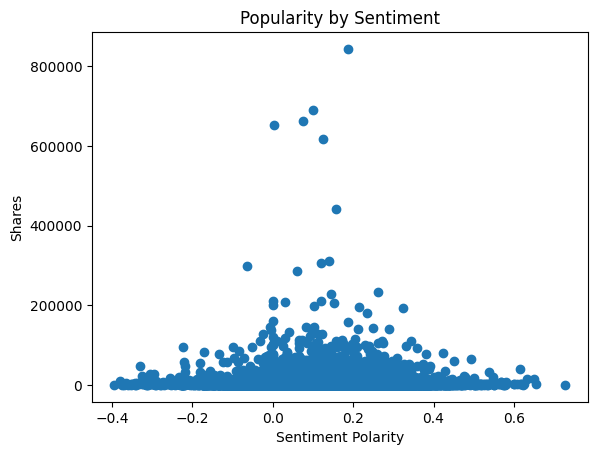

In [2]:
import pandas as pd
news=pd.read_csv('OnlineNewsPopularity.csv')

from matplotlib import pyplot as plt
plt.scatter(news[' global_sentiment_polarity'],news[' shares'])
plt.title('Popularity by Sentiment')
plt.xlabel('Sentiment Polarity')
plt.ylabel('Shares')
plt.show()

The plot shows no clear linear relationship between sentiment and shares. Neutral articles seem to get the most shares. A linear regression tests this more rigorously.

In [3]:
from sklearn.linear_model import LinearRegression
x = news[' global_sentiment_polarity'].values.reshape(-1,1)
y = news[' shares'].values.reshape(-1,1)
regressor = LinearRegression()
regressor.fit(x, y)
print(regressor.coef_)
print(regressor.intercept_)

[[499.34840588]]
[3335.80329021]


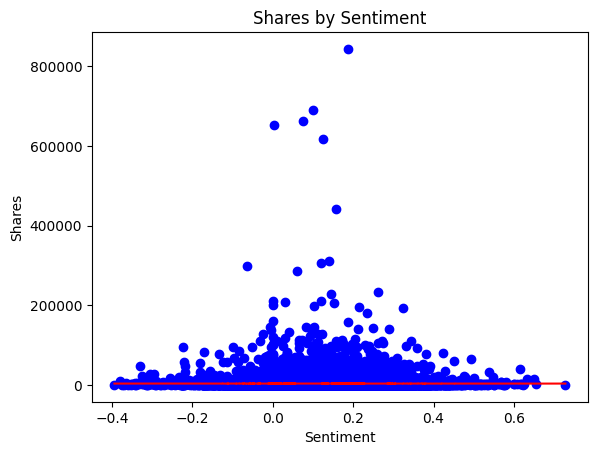

In [4]:
regline=regressor.predict(x)
plt.scatter(news[' global_sentiment_polarity'],news[' shares'],color='blue')
plt.plot(sorted(news[' global_sentiment_polarity'].tolist()),regline,'r')
plt.title('Shares by Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Shares')
plt.show()

The regression line is almost flat (shares = 3335.8 + 499.3 · sentiment), so linear regression predicts nearly the same number of shares for every article. Next we try k-nearest neighbors: predict a new article's shares from the average shares of the 15 articles with the most similar sentiment.

In [5]:
k=15
newsentiment=0.5
allsentiment=news[' global_sentiment_polarity'].tolist()
allshares=news[' shares'].tolist()
distances=[abs(x-newsentiment) for x in allsentiment]

import numpy as np
idx = np.argsort(distances)
print(idx[0:k])
nearbyshares=[allshares[i] for i in idx[0:k]]
print(np.mean(nearbyshares))

[30230 29598 22546  7284 13035 19361 36029 30670 25556  6744 26473  7211
  9200 15198 31496]
7344.466666666666


In [6]:
from sklearn.neighbors import KNeighborsRegressor
x=np.array(allsentiment).reshape(-1,1)
y=np.array(allshares)
knnregressor = KNeighborsRegressor(n_neighbors=15)
knnregressor.fit(x,y)
print(knnregressor.predict(np.array([newsentiment]).reshape(1,-1)))

[7344.46666667]


Five supervised learning methods, same feature and target, different learned functions:

In [7]:
# linear regression
from sklearn.linear_model import LinearRegression
regressor = LinearRegression()
regressor.fit(np.array(allsentiment).reshape(-1,1), np.array(allshares))
print(regressor.predict(np.array([newsentiment]).reshape(1,-1)))

# knn
from sklearn.neighbors import KNeighborsRegressor
knnregressor = KNeighborsRegressor(n_neighbors=15)
knnregressor.fit(np.array(allsentiment).reshape(-1,1), np.array(allshares))
print(knnregressor.predict(np.array([newsentiment]).reshape(1,-1)))

# decision tree
from sklearn.tree import DecisionTreeRegressor
dtregressor = DecisionTreeRegressor(max_depth=3)
dtregressor.fit(np.array(allsentiment).reshape(-1,1), np.array(allshares))
print(dtregressor.predict(np.array([newsentiment]).reshape(1,-1)))

# random forest
from sklearn.ensemble import RandomForestRegressor
rfregressor = RandomForestRegressor()
rfregressor.fit(np.array(allsentiment).reshape(-1,1), np.array(allshares))
print(rfregressor.predict(np.array([newsentiment]).reshape(1,-1)))

# neural network
from sklearn.neural_network import MLPRegressor
nnregressor = MLPRegressor()
nnregressor.fit(np.array(allsentiment).reshape(-1,1), np.array(allshares))
print(nnregressor.predict(np.array([newsentiment]).reshape(1,-1)))

[3585.47749315]
[7344.46666667]
[3978.70776621]
[4178.97160551]
[3970.41505009]


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


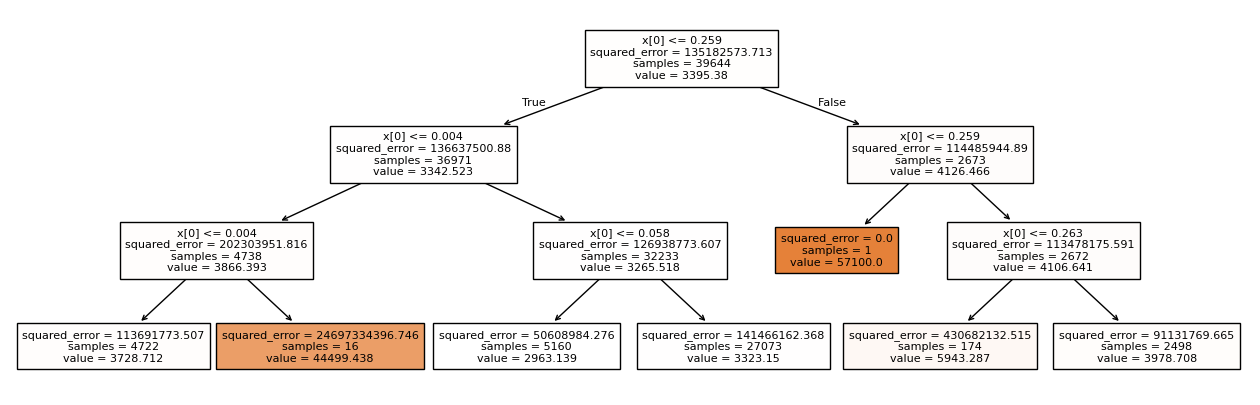

In [8]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
plt.figure(figsize=(16,5))
plot_tree(dtregressor, filled=True, fontsize=8)
plt.savefig('decisiontree.png')


Decision trees are easy to explain. Random forests average many trees and are usually more accurate but harder to interpret. Neural networks are powerful but hard to interpret. Next: measure accuracy with mean absolute error (MAE).

In [9]:
allprediction=regressor.predict(np.array([allsentiment]).reshape(-1,1))
predictionerror=abs(allprediction-allsentiment)
print(np.mean(predictionerror))


3395.26087436506


Measuring error on the same data used for training is "postdiction" and can hide overfitting. So we split the data randomly into a training set (75%) and a test set (25%).

In [10]:
from sklearn.model_selection import train_test_split
x=np.array([allsentiment]).reshape(-1,1)
y=np.array(allshares)
trainingx,testx,trainingy,testy=train_test_split(x,y,random_state=1)

print(len(trainingx))
print(len(trainingy))
print(len(testx))
print(len(testy))

29733
29733
9911
9911


In [11]:
rfregressor = RandomForestRegressor(random_state=1)
rfregressor.fit(trainingx, trainingy)
predicted = rfregressor.predict(testx)
predictionerror = abs(predicted-testy)
print("Random Forest mean absolute prediction error: ", np.mean(predictionerror))

knnregressor = KNeighborsRegressor(n_neighbors=15)
knnregressor.fit(trainingx, trainingy)
predicted = knnregressor.predict(testx)
predictionerror = abs(predicted-testy)
print("K Nearest Neighbor mean absolute prediction error: ", np.mean(predictionerror))

print(np.mean(predictionerror))

Random Forest mean absolute prediction error:  3813.8570912000264
K Nearest Neighbor mean absolute prediction error:  3292.4018834291865
3292.4018834291865


k-NN beats the random forest on the test set. Next, a multivariate model with three features.

In [12]:
x=news[[' global_sentiment_polarity',' n_unique_tokens',' n_non_stop_words']]
y=np.array(allshares)
trainingx,testx,trainingy,testy=train_test_split(x,y,random_state=1)
from sklearn.ensemble import RandomForestRegressor
rfregressor = RandomForestRegressor(random_state=1)
rfregressor.fit(trainingx, trainingy)
predicted = rfregressor.predict(testx)
predictionerror = abs(predicted-testy)
print("Multivariate random forest mean absolute prediction errror: ", np.mean(predictionerror))

Multivariate random forest mean absolute prediction errror:  3474.231759738627


Classification instead of regression: predict only whether an article gets more shares than the median.

In [13]:
themedian=np.median(news[' shares'])
news['abovemedianshares']=1*(news[' shares']>themedian)

x=news[[' global_sentiment_polarity',' n_unique_tokens',' n_non_stop_words']]
y=np.array(news['abovemedianshares'])
from sklearn.neighbors import KNeighborsClassifier
knnclassifier = KNeighborsClassifier(n_neighbors=15)
trainingx,testx,trainingy,testy=train_test_split(x,y,random_state=1)
knnclassifier.fit(trainingx, trainingy)
predicted = knnclassifier.predict(testx)

In [14]:
from sklearn.metrics import confusion_matrix
print(confusion_matrix(testy,predicted))


from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
precision = precision_score(testy,predicted)
recall = recall_score(testy,predicted)
print("Precision: ", precision)
print("Recall: ", recall)

[[2703 2280]
 [2370 2558]]
Precision:  0.5287308805291443
Recall:  0.5190746753246753


Conclusion:
Linear regression fit poorly. k-NN, decision trees, random forests and neural networks are other ways to learn the same mapping. On the test set, k-NN had the lowest error (about 3,292), and adding features improved the random forest (3,814 → 3,474). As a classifier, k-NN reached about 0.53 precision and 0.52 recall. Shares are hard to predict, but the models still help choose articles.